**Project Overview**

This notebook analyzes the output of AnyLogic simulation of a steel manufacturing plant (Discrete-Event production line + System Dynamics quality rework submodel).

Import the Python libra (pandas and matplotlib) and load the results (simulation_run_anylogic.csv), which cover input rate sweep from 0.5 to 10.0 units/hour across 500 simulation iterations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("simulation_run_anylogic.csv")
df.head()

,input_rate_per_hr,standard_slabs,coils_produced,refurbished_slabs,total_production,avg_slab_processing_hrs,crane_utilization_pct
0,0.5,59,38,3,100,2.35,14.2
1,1.0,112,73,6,191,2.52,22.8
2,1.5,174,113,9,296,2.71,31.5
3,2.0,227,148,12,387,2.89,39.4
4,2.5,289,188,15,492,3.08,47.6


**Verifying the System Dynamics Quality & Rework Submodel**

Check the dataset to confirm that the simulated rework percentage aligns with the 5% defect rule.

In [5]:
# Calculate total slabs cast (standard slabs + slabs sent to rework)
total_slabs_cast = df["standard_slabs"] + df["refurbished_slabs"]

# Compute the rework percentage for each experiment run
df["rework_pct"] = (df["refurbished_slabs"] / total_slabs_cast) * 100

avg_rework = round(df["rework_pct"].mean(), 2)
print("Average Rework Rate across all runs:", avg_rework, "%")

Average Rework Rate across all runs: 5.0 %


**Finding the Optimal Input Rate** (Bottleneck Analysis)

The production line relies on 2 overhead cranes subject to scheduled maintenance every 4 days and random breakdowns (MTTF = 5 days, MTTR = 1 day). Pushing the input rate too high overloads the cranes and causes slab waiting times to increase.

So best aproache here is to filter for runs where average slab processing time stays within an acceptable threshold (≤ 5.5 hours) and identify the arrival rate that maximizes total output.

In [6]:
good_runs = df[df["avg_slab_processing_hrs"] <= 5.5]
best_run = good_runs.sort_values(by="total_production", ascending=False).iloc[0]

print("--- Best Operating Point (500 Iterations Sweep) ---")
print("Input Rate (units/hr):", best_run["input_rate_per_hr"])
print("Total Production:", int(best_run["total_production"]))
print("Standard Slabs:", int(best_run["standard_slabs"]))
print("Coils Produced:", int(best_run["coils_produced"]))
print("Refurbished Slabs:", int(best_run["refurbished_slabs"]))
print("Avg Slab Time (hrs):", best_run["avg_slab_processing_hrs"])

--- Best Operating Point (500 Iterations Sweep) ---
Input Rate (units/hr): 6.5
Total Production: 1257
Standard Slabs: 737
Coils Produced: 481
Refurbished Slabs: 39
Avg Slab Time (hrs): 5.24


**Visualization**:
Chart 1: Total Production vs. Input Rate

This chart tracks total finished output across all input rates. Notice how production grows steadily up to 6.5 units/hour, after which the curve flattens because the 2 cranes reach maximum capacity.

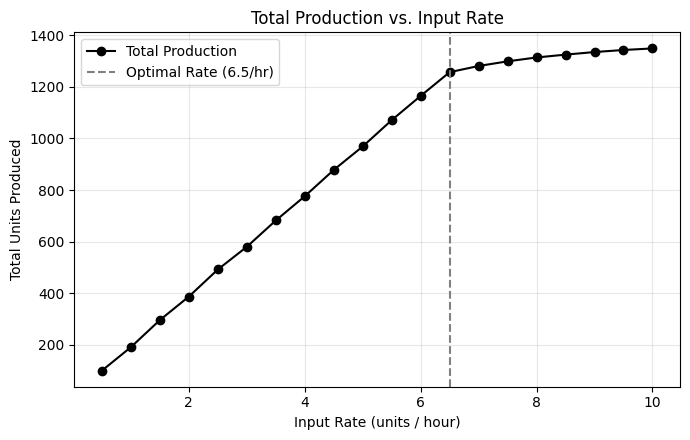

In [7]:
plt.figure(figsize=(7, 4.5))

plt.plot(df["input_rate_per_hr"], df["total_production"], marker="o", color="black", label="Total Production")
plt.axvline(best_run["input_rate_per_hr"], color="gray", linestyle="--", label="Optimal Rate (6.5/hr)")

plt.title("Total Production vs. Input Rate")
plt.xlabel("Input Rate (units / hour)")
plt.ylabel("Total Units Produced")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("chart1_total_production.png", dpi=150)
plt.show()

**Chart 2: Production Breakdown by Product Type**

To match the color-coded Statecharts in AnyLogic 2D animation, this chart separates total output into the three distinct finished product types: Standard Slabs (Blue), Coils (Orange), and Refurbished Slabs from the rework loop (Green).

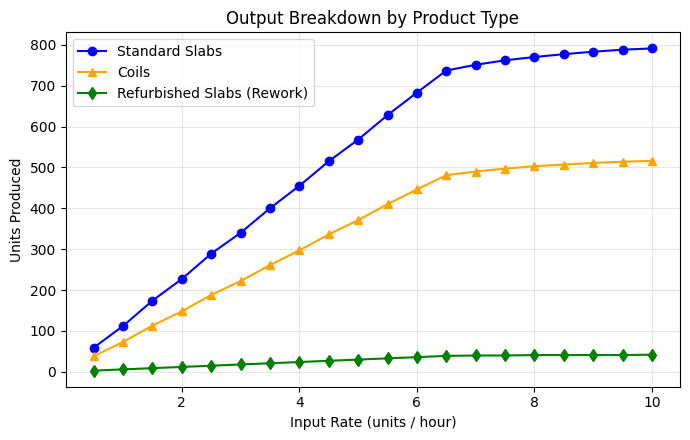

In [8]:
plt.figure(figsize=(7, 4.5))

plt.plot(df["input_rate_per_hr"], df["standard_slabs"], marker="o", color="blue", label="Standard Slabs")
plt.plot(df["input_rate_per_hr"], df["coils_produced"], marker="^", color="orange", label="Coils")
plt.plot(df["input_rate_per_hr"], df["refurbished_slabs"], marker="d", color="green", label="Refurbished Slabs (Rework)")

plt.title("Output Breakdown by Product Type")
plt.xlabel("Input Rate (units / hour)")
plt.ylabel("Units Produced")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("chart2_product_breakdown.png", dpi=150)
plt.show()

**Chart 3: Slab Processing Time & Crane Bottleneck**

The average processing time per slab as arrival speed increases. Beyond 6.5 units/hour, crane maintenance and breakdown downtime create a queue bottleneck, causing average processing time to climb steeply from ~5.2 hours to nearly 12 hours.

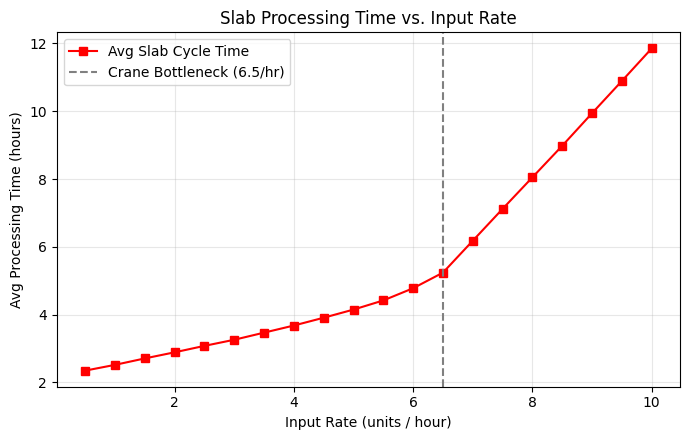

In [9]:
plt.figure(figsize=(7, 4.5))

plt.plot(df["input_rate_per_hr"], df["avg_slab_processing_hrs"], marker="s", color="red", label="Avg Slab Cycle Time")
plt.axvline(best_run["input_rate_per_hr"], color="gray", linestyle="--", label="Crane Bottleneck (6.5/hr)")

plt.title("Slab Processing Time vs. Input Rate")
plt.xlabel("Input Rate (units / hour)")
plt.ylabel("Avg Processing Time (hours)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("chart3_processing_time.png", dpi=150)
plt.show()